<a href="https://colab.research.google.com/github/Usermer/-Medical-Appointment-Management-System/blob/main/notebook1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [47]:
sap_hardcore=pd.read_excel('sap_hardcore_dataset.xlsx')
sap_hardcore.head()

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise
0,INV-1001,13/11/2024,2024-06-13,S-2,ACME SA,6657.55,USD,C-10,CC-123,4000,90D,XX,REF-172,MA,NaN
1,INV-1002,19/10/2024,2024-10-28,S-3,ACME SA,6582.9,USD,C-25,CC-842,6000,30D,KR,REF-56,US,NaN
2,INV-1003,14/1/2024,2024-02-04,S-50,Initech Ltd,8572.48,NaN,C-3,CC-441,5000,NaN,XX,REF-131,DE,NaN
3,INV-1004,7/7/2024,2024-08-01,S-2,Globex Corp,5298.27,NaN,C-20,CC-758,XXXX,90D,XX,REF-16,MA,NaN
4,INV-1005,21/11/2024,2024-07-02,S-1,Globex Corp,4345.08,NaN,C-29,CC-818,4000,60D,KR,REF-98,MA,random_text


In [48]:
sap_hardcore.columns

Index(['invoice_id', 'invoice_date', 'posting_date', 'supplier_id',
       'supplier_name', 'amount', 'currency', 'contract_id', 'cost_center',
       'gl_account', 'payment_terms', 'document_type', 'reference', 'country',
       'extra_noise'],
      dtype='object')

### Explication des Colonnes

| Colonne        | Description                                    |
|---------------|------------------------------------------------|
| `invoice_id`  | Identifiant unique de la facture               |
| `invoice_date`| Date d'émission de la facture                  |
| `posting_date`| Date de comptabilisation (enregistrement en compta)|
| `supplier_id` | Identifiant du fournisseur                     |
| `supplier_name`| Nom du fournisseur                             |
| `amount`      | Montant de la facture                          |
| `currency`    | Devise                                         |
| `contract_id` | Identifiant du contrat associé                 |
| `cost_center` | Centre de coût (département/unité budgétaire)  |
| `gl_account`  | Compte comptable général                       |
| `payment_terms`| Conditions de paiement (ex: 30J, 60J, 90J)     |
| `document_type`| Type de document                               |
| `reference`   | Référence externe/documentaire                 |
| `country`     | Pays                                           |
| `extra_noise` | Colonne "bruit"                               |

Donc on a 500 enregistrements avec 15 colonnes

 **- 1.Inspection générale du dataset**

In [49]:
sap_hardcore.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   invoice_id     475 non-null    object        
 1   invoice_date   500 non-null    object        
 2   posting_date   500 non-null    datetime64[ns]
 3   supplier_id    500 non-null    object        
 4   supplier_name  500 non-null    object        
 5   amount         500 non-null    object        
 6   currency       409 non-null    object        
 7   contract_id    429 non-null    object        
 8   cost_center    500 non-null    object        
 9   gl_account     393 non-null    object        
 10  payment_terms  361 non-null    object        
 11  document_type  500 non-null    object        
 12  reference      455 non-null    object        
 13  country        500 non-null    object        
 14  extra_noise    100 non-null    object        
dtypes: datetime64[ns](1), o

In [50]:
sap_hardcore.shape

(500, 15)

In [51]:
sap_hardcore.dtypes

,0
invoice_id,object
invoice_date,object
posting_date,datetime64[ns]
supplier_id,object
supplier_name,object
amount,object
currency,object
contract_id,object
cost_center,object
gl_account,object


 **-2. Analyse des valeurs manquantes**

In [52]:
missing_values=sap_hardcore.isnull().sum()
missing_values[missing_values>0]

,0
invoice_id,25
currency,91
contract_id,71
gl_account,107
payment_terms,139
reference,45
extra_noise,400


In [53]:
#en pourcentage
missing_pct=sap_hardcore.isnull().sum()/len(sap_hardcore)*100
missing_pct[missing_pct>0].sort_values(ascending=False)

,0
extra_noise,80.0
payment_terms,27.8
gl_account,21.4
currency,18.2
contract_id,14.2
reference,9.0
invoice_id,5.0


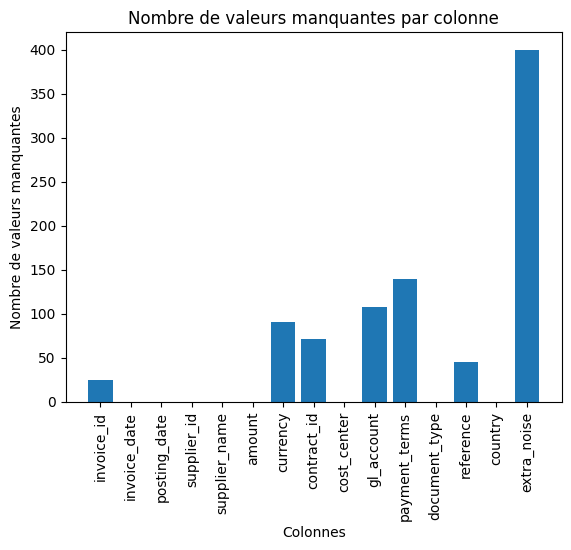

In [54]:
plt.bar(missing_values.index, missing_values.values)
plt.xlabel('Colonnes')
plt.ylabel('Nombre de valeurs manquantes')
plt.title('Nombre de valeurs manquantes par colonne')
plt.xticks(rotation=90)
plt.show()

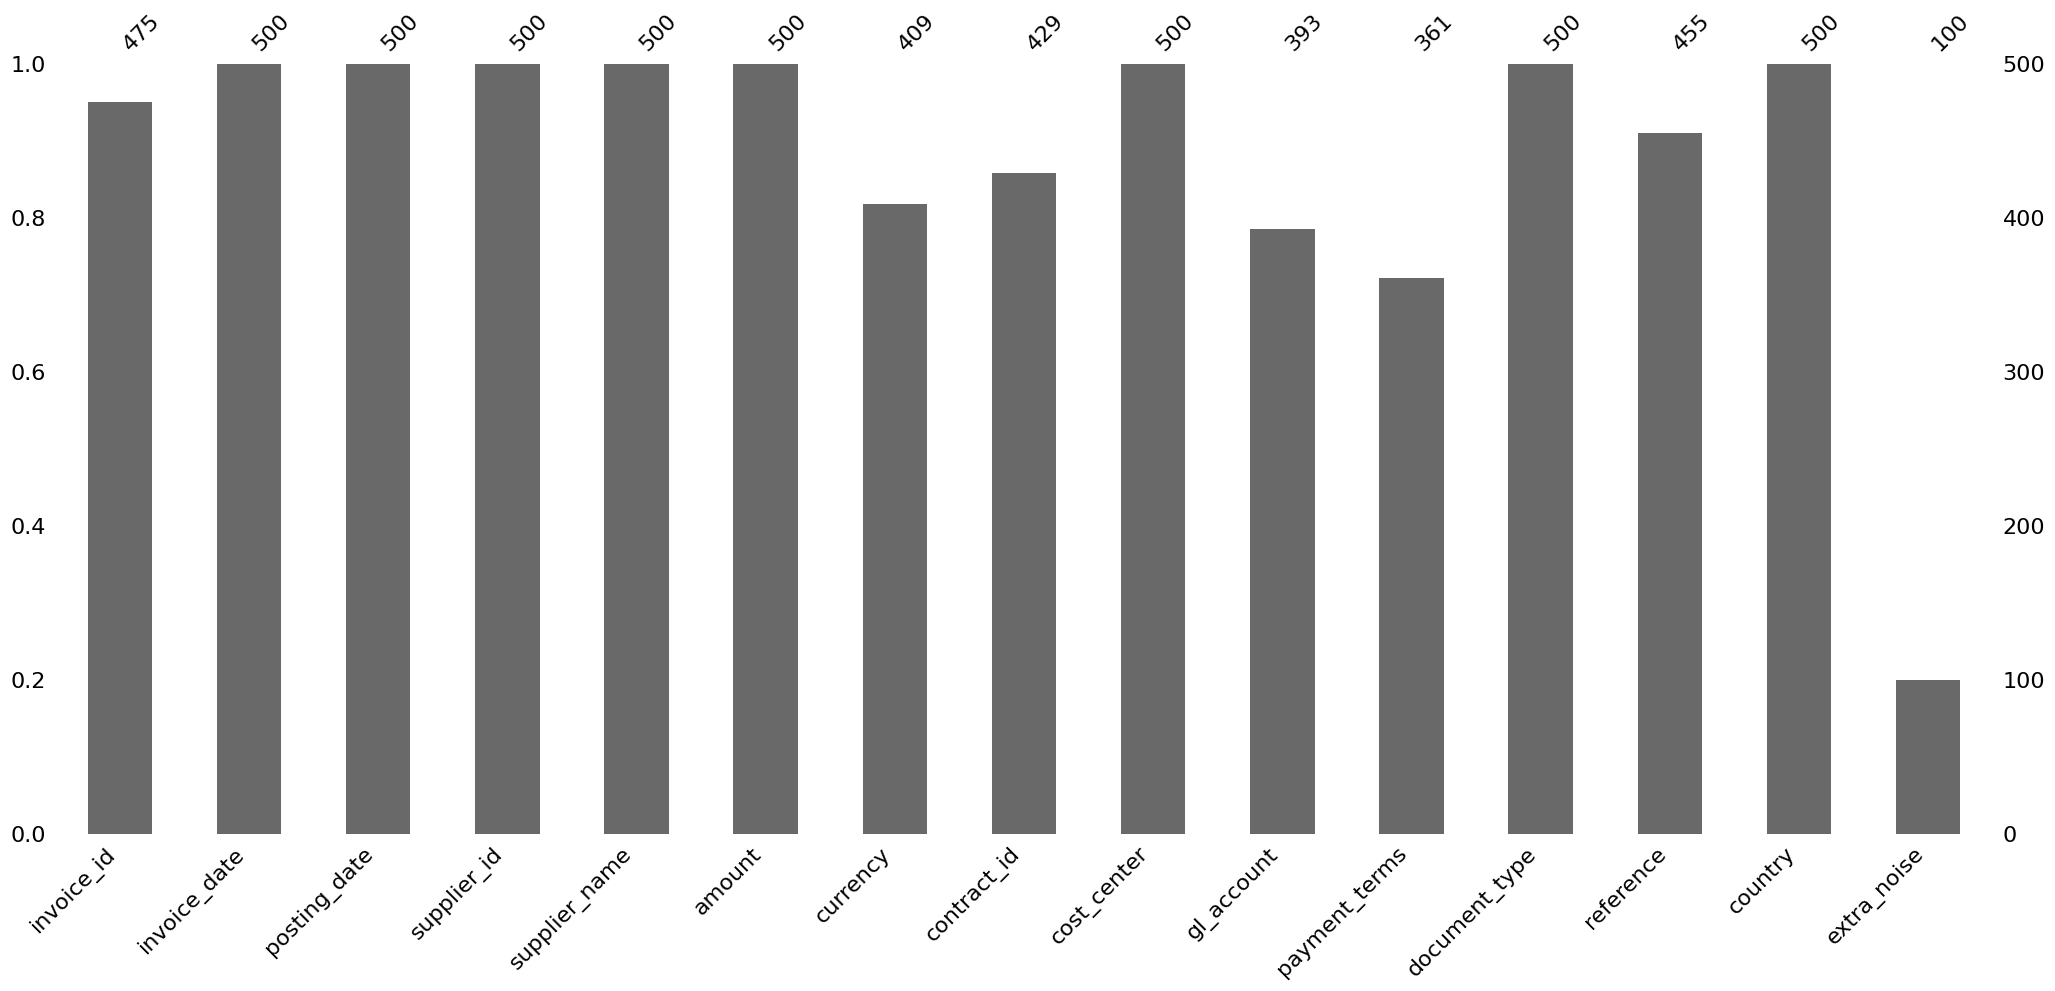

In [55]:
#diagramme en barres (proportion de non-null par colonne)
msno.bar(sap_hardcore)
plt.show()

In [56]:
rows_with_null_invoice_id = sap_hardcore[sap_hardcore['invoice_id'].isnull()]
display(rows_with_null_invoice_id.head())

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise
19,NaN,17/4/2024,2024-06-20,S-36,Initech Ltd,8756.83,USD,C-22,CC-277,5000,60D,KR,REF-139,DE,random_text
39,NaN,18/1/2024,2024-11-13,S-48,Globex Corp,609.77,EUR,C-18,CC-920,XXXX,30D,RE,REF-192,DE,random_text
59,NaN,2024-08-24 00:00:00,2024-03-05,S-26,Initech Ltd,3276.98,NaN,C-26,CC-412,4000,NaN,AB,REF-131,US,random_text
79,NaN,8/8/2024,2024-04-09,S-31,Initech Ltd,4659.99,MAD,C-27,CC-298,5000,30D,RE,REF-115,MA,random_text
99,NaN,6/5/2024,2024-12-11,S-1,Soylent Corp,-3959,MAD,C-5,CC-631,6000,60D,KR,REF-39,US,random_text


In [57]:
sap_hardcore.iloc[17:21]

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise
17,INV-1018,2024-10-26 00:00:00,2024-07-07,S-38,Globex Corp,3115.98,NaN,C-9,UNKNOWN,5000,60D,AB,REF-105,US,NaN
18,INV-1019,12/4/2024,2024-12-25,S-27,Umbrella Inc,3805.9,USD,C-5,CC-678,XXXX,30D,RE,REF-66,MA,NaN
19,NaN,17/4/2024,2024-06-20,S-36,Initech Ltd,8756.83,USD,C-22,CC-277,5000,60D,KR,REF-139,DE,random_text
20,INV-1021,11/8/2024,2024-03-21,S-50,Globex Corp,5558.62,GBP,NaN,CC-171,4000,30D,RE,REF-50,MA,NaN


In [58]:
sap_hardcore.iloc[37:40]

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise
37,INV-1038,25/2/2024,2024-05-09,S-9,Soylent Corp,9315.24,USD,C-5,CC-475,NaN,30D,XX,REF-119,US,NaN
38,INV-1039,11/5/2024,2024-06-12,S-42,Umbrella Inc,error_amount,NaN,C-2,CC-345,NaN,NaN,AB,REF-88,ES,NaN
39,NaN,18/1/2024,2024-11-13,S-48,Globex Corp,609.77,EUR,C-18,CC-920,XXXX,30D,RE,REF-192,DE,random_text


In [59]:
#donc pour les invoice id manquants on les remplace par INV-10+row+1

In [60]:
sap_hardcore.iloc[3:7]
#je pense qu'il suffit juste d'attribuer des ids uniques


,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise
3,INV-1004,7/7/2024,2024-08-01,S-2,Globex Corp,5298.27,NaN,C-20,CC-758,XXXX,90D,XX,REF-16,MA,NaN
4,INV-1005,21/11/2024,2024-07-02,S-1,Globex Corp,4345.08,NaN,C-29,CC-818,4000,60D,KR,REF-98,MA,random_text
5,INV-1006,2024-02-22 00:00:00,2024-02-06,S-33,ACME SA,6527,MAD,C-4,CC-147,5000,60D,RE,REF-132,ES,NaN
6,INV-1007,15/4/2024,2024-10-23,S-23,Initech Ltd,4450.67,NaN,NaN,CC-895,6000,NaN,XX,REF-144,ES,NaN


**3.Analyse des doublons**

In [61]:
doublons=sap_hardcore.duplicated().sum()/len(sap_hardcore)*100
doublons
#le dataset ne contient aucun doublons


np.float64(0.0)

**4. Analyse des types et formats**

In [62]:
sap_hardcore.dtypes

,0
invoice_id,object
invoice_date,object
posting_date,datetime64[ns]
supplier_id,object
supplier_name,object
amount,object
currency,object
contract_id,object
cost_center,object
gl_account,object


* Colonnes dates avec formats hétérogènes (invoice_date)
* invoice date et posting date doivent etre les deux de type datetime pour pouvoir effectuer des operations mathematiques
* amount->float
* gl account ->int

In [106]:
sap_hardcore['amount']=pd.to_numeric(sap_hardcore['amount'],errors='coerce')
sap_hardcore['gl_account']=pd.to_numeric(sap_hardcore['gl_account'],errors='coerce')

In [108]:
# sap_hardcore.dtypes

In [71]:
sap_hardcore.iloc[15:18]

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise
15,INV-1016,23/4/2024,2024-10-08,S-8,Soylent Corp,721.37,NaN,C-10,CC-862,NaN,30D,RE,REF-112,US,NaN
16,INV-1017,2024-15-40,2024-10-03,S-7,Initech Ltd,3239.87,GBP,C-11,CC-146,5000,90D,AB,REF-128,MA,NaN
17,INV-1018,2024-10-26 00:00:00,2024-07-07,S-38,Globex Corp,3115.98,NaN,C-9,UNKNOWN,5000,60D,AB,REF-105,US,NaN


aussi on constate que dans ces 3 lignes de invoice date chacune a son format

C'est un signal fort que cette colonne vient de sources hétérogènes

Calcul de nomre de lignes contenant des dates invalides

In [72]:
# 1. Convertir invoice_date en gardant une trace de la version originale
sap_hardcore['invoice_date_clean'] = pd.to_datetime(sap_hardcore['invoice_date'], dayfirst=True, errors='coerce')

# 2. Compter les dates invalides (devenues NaT après conversion)
nb_invalid = sap_hardcore['invoice_date_clean'].isnull().sum()
nb_total = len(sap_hardcore)
pct_invalid = (nb_invalid / nb_total) * 100

print(f"Nombre de dates invalides : {nb_invalid} / {nb_total}")
print(f"Pourcentage de dates invalides : {pct_invalid:.2f}%")

Nombre de dates invalides : 29 / 500
Pourcentage de dates invalides : 5.80%


In [73]:
sap_hardcore[sap_hardcore['invoice_date_clean'].isnull()]

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise,invoice_date_clean
16,INV-1017,2024-15-40,2024-10-03,S-7,Initech Ltd,3239.87,GBP,C-11,CC-146,5000,90D,AB,REF-128,MA,NaN,NaT
33,INV-1034,2024-15-40,2024-03-16,S-19,Initech Ltd,7816.24,USD,C-25,CC-409,4000,NaN,XX,REF-7,DE,NaN,NaT
50,INV-1051,2024-15-40,2024-10-01,S-10,Initech Ltd,7451.72,GBP,C-20,CC-557,NaN,90D,KR,REF-10,MA,NaN,NaT
67,INV-1068,2024-15-40,2024-05-08,S-46,Soylent Corp,4831.68,NaN,C-12,CC-274,6000,30D,AB,REF-170,FR,NaN,NaT
84,INV-1085,2024-15-40,2024-12-25,S-19,ACME SA,108.99,USD,C-27,CC-609,6000,NaN,AB,REF-164,FR,random_text,NaT
101,INV-1102,2024-15-40,2024-11-09,S-10,Soylent Corp,5963.78,EUR,C-5,CC-184,4000,30D,RE,REF-190,US,NaN,NaT
118,INV-1119,2024-15-40,2024-12-07,S-40,Umbrella Inc,5215.6,EUR,NaN,CC-606,5000,NaN,KR,REF-189,FR,NaN,NaT
135,INV-1136,2024-15-40,2024-07-25,S-5,Umbrella Inc,7837.44,NaN,C-6,CC-581,XXXX,30D,KR,REF-85,MA,NaN,NaT
152,INV-1153,2024-15-40,2024-03-13,S-15,Umbrella Inc,6872.83,NaN,C-9,UNKNOWN,XXXX,90D,KR,REF-27,FR,NaN,NaT
169,INV-1170,2024-15-40,2024-09-15,S-38,Initech Ltd,3300.74,GBP,C-15,CC-958,5000,90D,AB,REF-39,ES,random_text,NaT


elles semblent avoir la meme date erronée

In [86]:
dates_invalides=sap_hardcore[sap_hardcore['invoice_date_clean'].isnull()]
date_invalides['invoice_date'].unique()
#y'a probleme dans une seule date

array(['2024-15-40'], dtype=object)

In [63]:
#colonnes categorielles
cat_cols=['currency','document_type','country']
for col in cat_cols:
  unique=sap_hardcore[col].unique()
  print(col,unique)

currency ['USD' nan 'MAD' 'GBP' 'EUR']
document_type ['XX' 'KR' 'RE' 'AB']
country ['MA' 'US' 'DE' 'ES' 'FR']


In [67]:
## Est-ce qu'un même fournisseur est toujours payé dans la même devise ?
sap_hardcore.groupby('supplier_id')['currency'].unique()


,currency
supplier_id,
S-1,"[nan, MAD, USD, EUR]"
S-10,"[USD, GBP, EUR]"
S-11,"[MAD, EUR, GBP, USD, nan]"
S-12,"[GBP, USD, MAD, EUR, nan]"
S-13,"[USD, GBP, nan, EUR, MAD]"
S-14,"[GBP, MAD, EUR, USD]"
S-15,"[EUR, nan, USD, GBP, MAD]"
S-16,"[MAD, USD, EUR, GBP]"
S-17,"[USD, nan, EUR, MAD, GBP]"


 nunique() est élevé (un même fournisseur facturé dans 3-4 devises différentes sans logique apparente), donc ça pencherait plutôt vers des données générées aléatoirement.

**5. Analyse statistique univariée**

In [68]:
sap_hardcore.describe()

,posting_date
count,500
mean,2024-07-08 13:26:24
min,2024-01-03 00:00:00
25%,2024-04-09 18:00:00
50%,2024-07-09 00:00:00
75%,2024-10-13 00:00:00
max,2024-12-28 00:00:00


**6. Analyse temporelle**
comparer invoice date  et posting_date

In [91]:
#normalement une facture doit être émise avant ou en même temps qu'elle soit comptabilisée. donc invoice date = < posting date
anomalie_temp=sap_hardcore['posting_date']<sap_hardcore['invoice_date_clean']
len(sap_hardcore[anomalie_temp]) #230


230

In [92]:
sap_hardcore[anomalie_temp]

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise,invoice_date_clean
0,INV-1001,13/11/2024,2024-06-13,S-2,ACME SA,6657.55,USD,C-10,CC-123,4000,90D,XX,REF-172,MA,NaN,2024-11-13
4,INV-1005,21/11/2024,2024-07-02,S-1,Globex Corp,4345.08,NaN,C-29,CC-818,4000,60D,KR,REF-98,MA,random_text,2024-11-21
5,INV-1006,2024-02-22 00:00:00,2024-02-06,S-33,ACME SA,6527,MAD,C-4,CC-147,5000,60D,RE,REF-132,ES,NaN,2024-02-22
7,INV-1008,17/9/2024,2024-07-25,S-26,ACME SA,4015.75,GBP,C-3,CC-848,6000,60D,AB,REF-67,ES,NaN,2024-09-17
11,INV-1012,2024-07-11 00:00:00,2024-03-12,S-43,ACME SA,8972.25,MAD,C-28,CC-595,NaN,NaN,RE,REF-12,FR,NaN,2024-07-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,INV-1494,18/7/2024,2024-05-22,S-28,Umbrella Inc,error_amount,GBP,C-30,CC-874,6000,NaN,KR,REF-143,US,NaN,2024-07-18
494,DUPL-100,8/11/2024,2024-02-20,S-27,ACME SA,2090.03,MAD,C-14,UNKNOWN,NaN,30D,KR,NaN,MA,random_text,2024-11-08
497,INV-1498,2024-05-05 00:00:00,2024-01-24,S-2,ACME SA,9446.01,GBP,C-12,CC-933,4000,60D,RE,REF-108,FR,NaN,2024-05-05
498,INV-1499,19/2/2024,2024-02-07,S-11,Soylent Corp,4809.89,EUR,C-4,CC-914,NaN,30D,RE,REF-93,ES,NaN,2024-02-19


**7. Analyse de cohérence croisée (cross-field validation)**

**Objectif de cette étape**

Vérifier que les valeurs de plusieurs colonnes, prises ensemble, sont logiquement cohérentes — car une valeur peut être valide individuellement, mais incohérente une fois croisée avec une autre colonne.

In [99]:
# 1. supplier_id ↔ supplier_name
incoherence_id=sap_hardcore.groupby('supplier_id')['supplier_name'].nunique()
incoherence_id[incoherence_id>1][:5]

,supplier_name
supplier_id,
S-1,4
S-10,3
S-11,5
S-12,5
S-13,4


In [ ]:
#2. country ↔ currency

In [66]:
sap_hardcore.groupby('country')['currency'].value_counts()[:4]

country  currency
DE       EUR         28
         MAD         20
         USD         19
         GBP         18
Name: count, dtype: int64

In [104]:
# contract_id ↔ payment_terms
#Si un contract_id a plusieurs payment_terms différents, c'est suspect (un contrat a normalement des conditions fixes).
sap_hardcore.groupby('contract_id')['payment_terms'].value_counts().sort_values(ascending=False)[:4]

,,count
contract_id,payment_terms,
C-12,30D,9
C-5,30D,9
C-25,90D,8
C-24,30D,8


**8. Détection d'anomalies préliminaires (règles simples)**

In [114]:
#Montants à 0 ou négatifs
sap_hardcore['amount'].min()
#le min est -4934 donc anomalie
montant_negatifs=sap_hardcore[sap_hardcore['amount']<0]
display(montant_negatifs)

,invoice_id,invoice_date,posting_date,supplier_id,supplier_name,amount,currency,contract_id,cost_center,gl_account,payment_terms,document_type,reference,country,extra_noise,invoice_date_clean
24,INV-1025,13/2/2024,2024-06-21,S-12,Umbrella Inc,-4455.0,USD,C-22,CC-284,5000.0,90D,RE,REF-96,US,random_text,2024-02-13
49,INV-1050,11/11/2024,2024-05-06,S-33,Globex Corp,-1690.0,GBP,C-5,CC-365,4000.0,NaN,AB,REF-110,DE,random_text,2024-11-11
74,INV-1075,27/7/2024,2024-02-25,S-26,ACME SA,-1466.0,NaN,C-16,CC-416,4000.0,NaN,RE,REF-107,ES,random_text,2024-07-27
99,NaN,6/5/2024,2024-12-11,S-1,Soylent Corp,-3959.0,MAD,C-5,CC-631,6000.0,60D,KR,REF-39,US,random_text,2024-05-06
124,INV-1125,17/11/2024,2024-08-24,S-40,Umbrella Inc,-4036.0,MAD,C-25,CC-544,NaN,90D,RE,REF-186,DE,random_text,2024-11-17
149,INV-1150,2024-01-14 00:00:00,2024-05-08,S-39,Initech Ltd,-4934.0,USD,C-29,CC-130,NaN,30D,XX,REF-33,MA,random_text,2024-01-14
174,INV-1175,5/5/2024,2024-06-11,S-26,Globex Corp,-2603.0,EUR,NaN,CC-294,6000.0,90D,RE,REF-178,ES,random_text,2024-05-05
199,NaN,11/6/2024,2024-06-25,S-50,ACME SA,-3472.0,GBP,C-18,CC-531,6000.0,NaN,RE,REF-107,MA,random_text,2024-06-11
224,INV-1225,10/5/2024,2024-02-20,S-33,ACME SA,-4332.0,USD,C-20,UNKNOWN,4000.0,NaN,KR,REF-133,FR,random_text,2024-05-10
249,INV-1250,10/3/2024,2024-07-17,S-1,Umbrella Inc,-3759.0,NaN,C-17,CC-309,NaN,60D,AB,REF-69,MA,random_text,2024-03-10


4000.0